# Bunny ($S^{1} \vee S^{2} \vee S^{1}$)

A wedge of two circles and a sphere. Extends the sphere $\vee$ circle example with two distinct $H^{1}$ generators.

In [3]:
from dreimac import ToroidalCoords
from dreimac.utils import CircleMapUtils
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from torofit.partition_utils import total_variation_scores
import torofit as TF

pio.renderers.default = "notebook_connected"

In [4]:
def generate_s1_s2_s1_point_cloud(n_points=1000, n_circle=500,
                                  sphere_radius=8, circle1_radius=5, circle2_radius=5.1,
                                  wedge_point=None,
                                  circle1_normal=None,
                                  circle2_normal=None,
                                  noise=0.05):
    """
    Generates a point cloud for S^1 ∨ S^2 ∨ S^1 with all three spaces
    wedged at a single point on the sphere.

    Each circle's plane passes through the wedge point and is perpendicular
    to its given normal vector.

    Parameters:
      n_points : int - number of points on the sphere
      n_circle : int - number of points per circle
      sphere_radius : float - radius of the sphere
      circle1_radius, circle2_radius : float - radii of the two circles
      wedge_point : 3D array - point on the sphere where all spaces meet
      circle1_normal : 3D array - normal to circle 1's plane
      circle2_normal : 3D array - normal to circle 2's plane

    Returns:
      point_cloud : (N x 3) numpy array
    """
    # 1. Sphere
    phi = np.random.uniform(0, 2 * np.pi, n_points)
    z = np.random.uniform(-1, 1, n_points)
    r = sphere_radius * np.sqrt(1 - z**2)
    sphere_points = np.column_stack((r * np.cos(phi), r * np.sin(phi), sphere_radius * z))

    # 2. Defaults
    if wedge_point is None:
        wedge_point = np.array([0, 0, sphere_radius])
    if circle1_normal is None:
        circle1_normal = np.array([0, 1, 0])
    if circle2_normal is None:
        circle2_normal = np.array([np.sin(np.pi/4), np.cos(np.pi/4), 0])

    angles = np.linspace(0, 2 * np.pi, n_circle, endpoint=False)

    def make_circle(p0, normal, radius, angles):
        """
        Circle of given radius in the plane through p0 with given normal,
        passing through p0.
        """
        p0 = np.array(p0, dtype=float)
        n = np.array(normal, dtype=float)
        n = n / np.linalg.norm(n)

        # Find two orthonormal vectors in the plane
        # Pick an arbitrary vector not parallel to n
        if abs(np.dot(n, [1, 0, 0])) < 0.9:
            aux = np.array([1, 0, 0])
        else:
            aux = np.array([0, 1, 0])

        e1 = np.cross(n, aux)
        e1 = e1 / np.linalg.norm(e1)
        e2 = np.cross(n, e1)
        e2 = e2 / np.linalg.norm(e2)

        # Center offset so circle passes through p0 at t=π
        center = p0 + radius * e1
        return np.array([
            center + radius * (np.cos(t) * e1 + np.sin(t) * e2)
            for t in angles
        ])

    circle1 = make_circle(wedge_point, circle1_normal, circle1_radius, angles)
    circle2 = make_circle(wedge_point, circle2_normal, circle2_radius, angles)
    point_cloud = np.vstack([sphere_points, circle1, circle2])
    point_cloud += np.random.normal(0, noise, point_cloud.shape)
    return point_cloud

# Circle 1 in the xz-plane, circle 2 rotated 45° about z
point_cloud= generate_s1_s2_s1_point_cloud(
    wedge_point=np.array([0, 0, 8]),
    circle1_normal=np.array([0, -1, 1]),      
    circle2_normal=np.array([0, -1, -1]),      
    noise=0.1)
# Visualize using Plotly's go.Figure
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=point_cloud[:, 0],
    y=point_cloud[:, 1],
    z=point_cloud[:, 2],
    mode='markers',
    marker=dict(
        size=2,
        color='#ff69b4',
        opacity=0.8
    ),
    name=r'$S^1 \vee S^2 \vee S^1$ (Radial Circles)'
))



fig.update_layout(
    title=r'Point Cloud for $S^1 \vee S^2 \vee S^1$ (Radial Circles)',
    scene=dict(
        xaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        yaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        zaxis=dict(
            showbackground=False,
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            visible=False
        )
    ),
    paper_bgcolor="white",
    plot_bgcolor="white"
)

fig.update_layout(
    scene=dict(
        aspectmode='manual',    # <— force equal scaling on x,y,z
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
    ),
    margin=dict(l=0,r=0,b=0,t=30),
    paper_bgcolor='white',
)

fig.show()

In [5]:
tc_bunny = ToroidalCoords(point_cloud, n_landmarks=1000)
tc_total_theta = tc_bunny.get_coordinates(cocycle_idxs=[0,1,])

Coordinate range: 0.009791983497166982 to 6.281183260905622


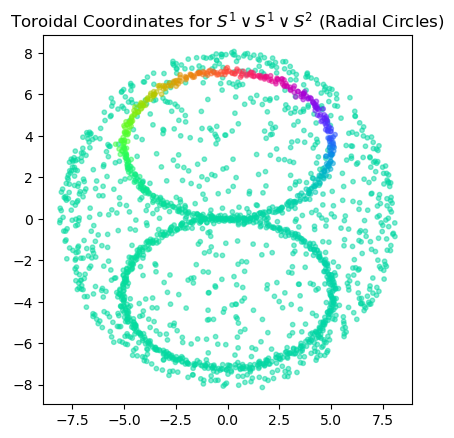

Coordinate range: 0.0016079895296917238 to 6.282907985875514


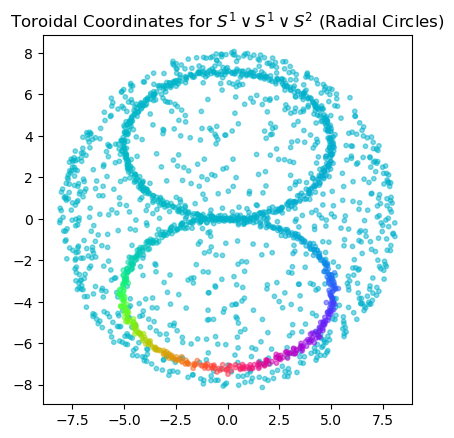

In [6]:
for coord in tc_total_theta:
    print(f'Coordinate range: {coord.min()} to {coord.max()}')
    plt.scatter(point_cloud[:,0], point_cloud[:,1], c=CircleMapUtils.to_sinebow(coord), s=10, alpha=0.5)
    plt.title(r'Toroidal Coordinates for $S^1 \vee S^1 \vee S^2$ (Radial Circles)')
    plt.gca().set_aspect('equal')
    plt.show()

In [7]:


part1 = total_variation_scores(0, tc_bunny, tc_total_theta)
part2 = total_variation_scores(1, tc_bunny, tc_total_theta)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)

thresh = [0.50, 0.50]
filter_for_low_raw_scores = np.linalg.norm(raw_scores, axis=1) > 0.1
n_parts = raw_scores.shape[1]

# Landmark-level assignment: confident points by threshold, middle points random.
assigned_part = -np.ones(raw_scores.shape[0], dtype=int)
for i in range(n_parts):
    confident_idx = np.where(
        np.logical_and(softmax_scores[:, i] >= thresh[i], filter_for_low_raw_scores)
    )[0]
    assigned_part[confident_idx] = i

middle_idx = np.where(np.logical_and(assigned_part == -1, filter_for_low_raw_scores))[0]
rng = np.random.default_rng()
assigned_part[middle_idx] = rng.integers(0, n_parts, size=middle_idx.size)

# Explicitly ignore low-score points that remain unassigned (-1).
valid_mask = assigned_part != -1
ignored_idx = np.where(~valid_mask)[0]
print(f"Ignored low-score landmarks: {len(ignored_idx)}")

parts = []
landmarks = tc_bunny._idx_land
for i in range(n_parts):
    print(f"Partition {i+1}, threshold: {thresh[i]}")
    good_idx = np.where(np.logical_and(assigned_part == i, valid_mask))[0]
    print(f"  confident+random landmarks in partition: {len(good_idx)}")

    if len(good_idx) == 0:
        parts.append(np.array([], dtype=int))
        continue

    good_landmarks = landmarks[good_idx]
    mems_for_good = tc_bunny._dist_land_data[good_idx, :]
    parts.append(np.where(np.any(mems_for_good < tc_bunny._r_cover, axis=0))[0])

[[0.50008422 0.49991578]
 [0.3340887  0.6659113 ]
 [0.49980412 0.50019588]
 ...
 [0.50004141 0.49995859]
 [0.49995508 0.50004492]
 [0.49376539 0.50623461]]
Ignored low-score landmarks: 858
Partition 1, threshold: 0.5
  confident+random landmarks in partition: 70
Partition 2, threshold: 0.5
  confident+random landmarks in partition: 72


(array([10., 15.,  6.,  4.,  4.,  3.,  5.,  2.,  2.,  2.,  2.,  0.,  2.,
         0.,  2.,  1.,  0.,  2.,  1.,  1.,  2.,  4.,  2.,  0.,  0.,  1.,
         4.,  2.,  1.,  3.,  1.,  1.,  1.,  2.,  0.,  0.,  2.,  0.,  2.,
         0.,  2.,  3.,  1.,  6.,  6.,  7.,  6.,  1., 10.,  8.]),
 array([0.31870531, 0.32614723, 0.33358914, 0.34103106, 0.34847297,
        0.35591489, 0.3633568 , 0.37079872, 0.37824063, 0.38568255,
        0.39312446, 0.40056638, 0.40800829, 0.41545021, 0.42289212,
        0.43033404, 0.43777595, 0.44521787, 0.45265978, 0.4601017 ,
        0.46754361, 0.47498553, 0.48242744, 0.48986936, 0.49731127,
        0.50475319, 0.5121951 , 0.51963701, 0.52707893, 0.53452084,
        0.54196276, 0.54940467, 0.55684659, 0.5642885 , 0.57173042,
        0.57917233, 0.58661425, 0.59405616, 0.60149808, 0.60893999,
        0.61638191, 0.62382382, 0.63126574, 0.63870765, 0.64614957,
        0.65359148, 0.6610334 , 0.66847531, 0.67591723, 0.68335914,
        0.69080106]),
 <BarContainer

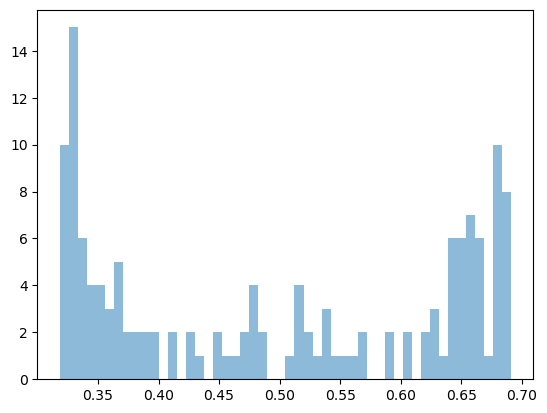

In [8]:
plt.hist(np.sort(softmax_scores[filter_for_low_raw_scores,0]), bins=50, alpha=0.5, label='Partition 1')

(array([ 8., 10.,  1.,  6.,  7.,  6.,  6.,  1.,  3.,  2.,  0.,  2.,  0.,
         2.,  0.,  0.,  2.,  1.,  1.,  1.,  3.,  1.,  2.,  4.,  1.,  0.,
         0.,  2.,  4.,  2.,  1.,  1.,  2.,  0.,  1.,  2.,  0.,  2.,  0.,
         2.,  2.,  2.,  2.,  5.,  3.,  4.,  4.,  6., 15., 10.]),
 array([0.30919894, 0.31664086, 0.32408277, 0.33152469, 0.3389666 ,
        0.34640852, 0.35385043, 0.36129235, 0.36873426, 0.37617618,
        0.38361809, 0.39106001, 0.39850192, 0.40594384, 0.41338575,
        0.42082767, 0.42826958, 0.4357115 , 0.44315341, 0.45059533,
        0.45803724, 0.46547916, 0.47292107, 0.48036299, 0.4878049 ,
        0.49524681, 0.50268873, 0.51013064, 0.51757256, 0.52501447,
        0.53245639, 0.5398983 , 0.54734022, 0.55478213, 0.56222405,
        0.56966596, 0.57710788, 0.58454979, 0.59199171, 0.59943362,
        0.60687554, 0.61431745, 0.62175937, 0.62920128, 0.6366432 ,
        0.64408511, 0.65152703, 0.65896894, 0.66641086, 0.67385277,
        0.68129469]),
 <BarContainer

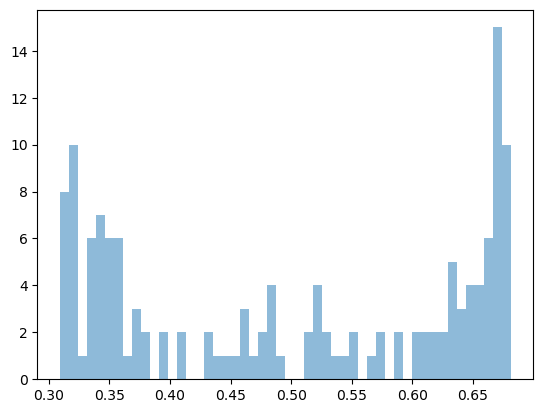

In [9]:
plt.hist(np.sort(softmax_scores[filter_for_low_raw_scores,1]), bins=50, alpha=0.5, label='Partition 2')

In [10]:


K = 20
part1 = total_variation_scores(0, tc_bunny, tc_total_theta, K=K)
part2 = total_variation_scores(1, tc_bunny, tc_total_theta, K=K)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)
CUTOFF = 0.5
thresh = [0.5,0.505]#[np.percentile(softmax_scores[:, i], 50) for i in range(softmax_scores.shape[1])]
LOW_SCORE_CUTOFF = 0.02
filter_for_low_raw_scores = np.linalg.norm(raw_scores, axis=1) > LOW_SCORE_CUTOFF
n_parts = raw_scores.shape[1]

# Landmark-level assignment: confident points by threshold, middle points random.
assigned_part = -np.ones(raw_scores.shape[0], dtype=int)
for i in range(n_parts):
    confident_idx = np.where(
        np.logical_and(softmax_scores[:, i] >= thresh[i], filter_for_low_raw_scores)
    )[0]
    assigned_part[confident_idx] = i

middle_idx = np.where(np.logical_and(assigned_part == -1, filter_for_low_raw_scores))[0]
# rng = np.random.default_rng()
# assigned_part[middle_idx] = rng.integers(0, n_parts, size=middle_idx.size)

# Explicitly ignore low-score points that remain unassigned (-1).
valid_mask = assigned_part != -1
ignored_idx = np.where(~valid_mask)[0]
print(f"Ignored low-score landmarks: {len(ignored_idx)}")

parts = []
landmarks = tc_bunny._idx_land
for i in range(n_parts):
    print(f"Partition {i+1}, threshold: {thresh[i]}")
    good_idx = np.where(np.logical_and(assigned_part == i, valid_mask))[0]
    print(f"  confident+random landmarks in partition: {len(good_idx)}")

    if len(good_idx) == 0:
        parts.append(np.array([], dtype=int))
        continue

    good_landmarks = landmarks[good_idx]
    mems_for_good = tc_bunny._dist_land_data[good_idx, :]
    parts.append(np.where(np.any(mems_for_good < tc_bunny._r_cover, axis=0))[0])

[[0.50000567 0.49999433]
 [0.47693205 0.52306795]
 [0.49991482 0.50008518]
 ...
 [0.49987728 0.50012272]
 [0.49994405 0.50005595]
 [0.49943715 0.50056285]]
Ignored low-score landmarks: 868
Partition 1, threshold: 0.5
  confident+random landmarks in partition: 66
Partition 2, threshold: 0.505
  confident+random landmarks in partition: 66


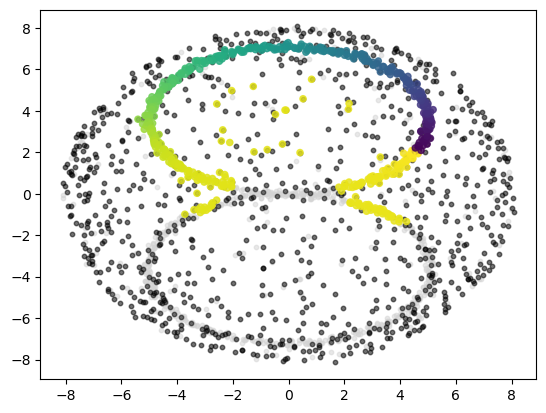

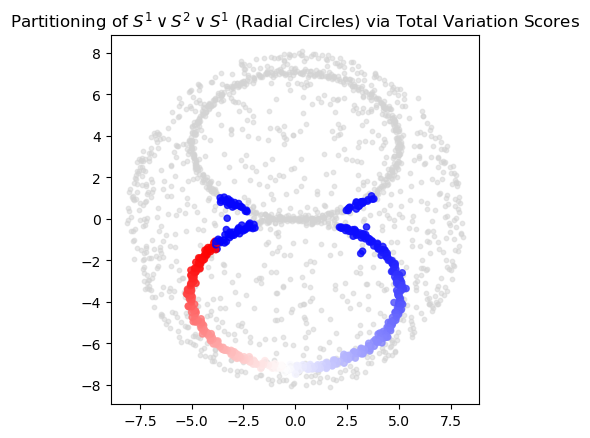

In [11]:
plt.scatter(point_cloud[:,0], point_cloud[:,1], c='lightgray', s=10, alpha=0.5)
plt.scatter(point_cloud[tc_bunny._idx_land,0], point_cloud[tc_bunny._idx_land,1], c='black', s=10, alpha=0.5)
plt.scatter(point_cloud[parts[0],0], point_cloud[parts[0],1], c=tc_total_theta[0][parts[0]], s=20, alpha=0.8)
plt.show()
plt.scatter(point_cloud[:,0], point_cloud[:,1], c='lightgray', s=10, alpha=0.5)
plt.scatter(point_cloud[parts[1],0], point_cloud[parts[1],1], c=tc_total_theta[1][parts[1]],cmap='bwr', s=20, alpha=0.8)
plt.title(r'Partitioning of $S^1 \vee S^2 \vee S^1$ (Radial Circles) via Total Variation Scores')
plt.gca().set_aspect('equal')
plt.show()  

In [12]:
Ks = [100,100]
lams=[5.0, 5.0]
circle_1_fit = TF.fit(point_cloud[parts[0],:], tc_total_theta[0][parts[0]], K=Ks[0], lam=lams[0])
circle_2_fit = TF.fit(point_cloud[parts[1],:], tc_total_theta[1][parts[1]], K=Ks[1], lam=lams[1])

In [13]:


def assembly(fit, theta,  K, wedge_point_coords, samples=100, wedge_point=np.array([0, 0, 8])):
    if theta is None:
        theta = np.linspace(0, 2*np.pi, num=samples).reshape(-1,1)
    image = TF.Toroidal_Evaluate(fit,theta + wedge_point_coords,K).real
    
    ## Fj(hj(wedge_point))
    offset = wedge_point - TF.Toroidal_Evaluate(fit, wedge_point_coords.reshape(1,-1), K=K).real
    image += offset
    return image

In [14]:
## Find index of wedge point in the initial point cloud
wedge_point = np.array([0, 0, 8])
wedge_idx = np.argmin(np.linalg.norm(point_cloud - wedge_point, axis=1))
wedge_point_coords = tc_total_theta[:, wedge_idx]

In [15]:
theta = np.linspace(0, 2*np.pi, num=100).reshape(-1,1)
res1 = assembly(circle_1_fit, theta, K=Ks[0], wedge_point_coords=wedge_point_coords[0])
res2 = assembly(circle_2_fit, theta, K=Ks[1], wedge_point_coords=wedge_point_coords[1])
fig = go.Figure(data=[ go.Scatter3d(
    x=point_cloud[:,0], y=point_cloud[:,1], z=point_cloud[:,2], 
    mode ='markers', 
    marker=dict(size = 2 , color='gray', opacity=0.3),
    name='Data'),
      go.Scatter3d(
    x=res1[:,0], y=res1[:,1], z=res1[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color=CircleMapUtils.to_sinebow(theta)[:,0]),
    name='Circle 1'),
     go.Scatter3d(
    x=res2[:,0]-0.05, y=res2[:,1], z=res2[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color=CircleMapUtils.to_sinebow(theta)[:,0]),
    name='Circle 2')
    ])


fig.update_layout(
    width=1200, height=600,
    scene=dict(
        camera=dict(eye=dict(x=0, y=-1, z=3)),
        xaxis=dict(
            showticklabels=False, # Hides the numerical labels
            ticks=""             # Hides the tick marks themselves
        ),
        yaxis=dict(
            showticklabels=False,
            ticks=""
        ),
        zaxis=dict(
            showticklabels=False,
            ticks=""
        )
    ),
    showlegend=True,
    font=dict(size=12)
)


fig.show()

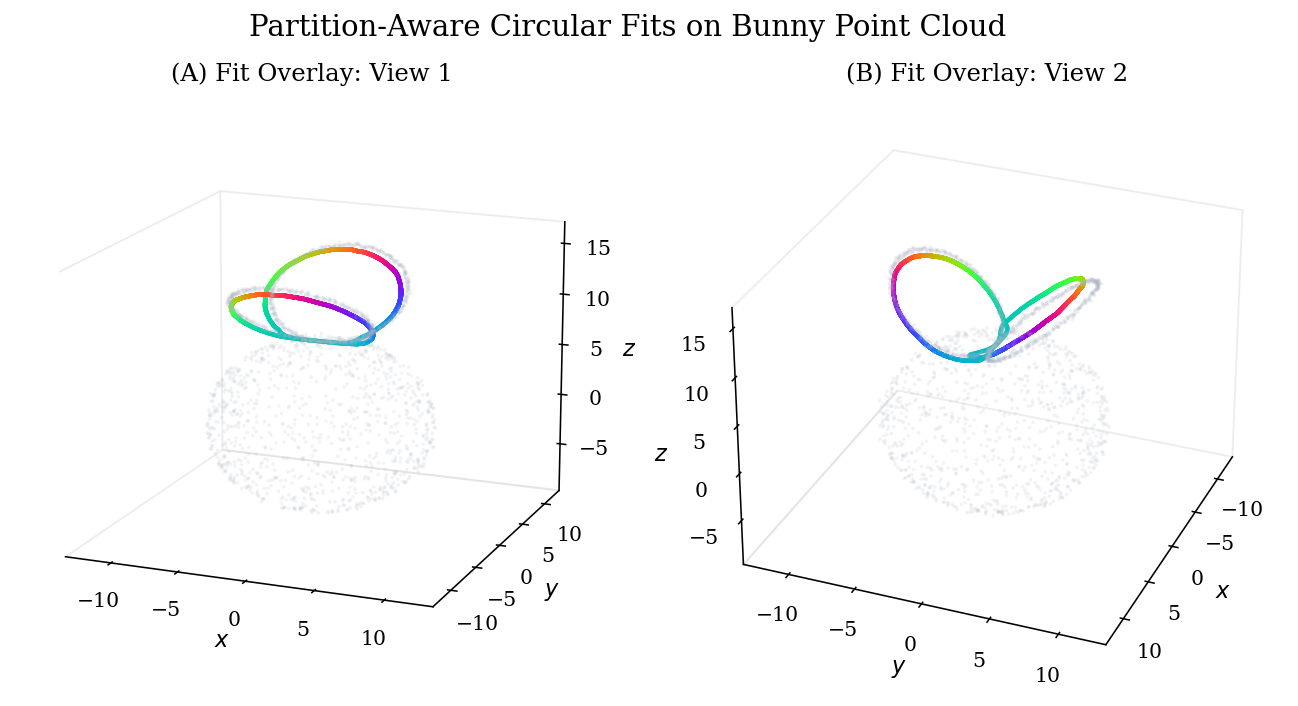

In [16]:
# Publication-ready static visualization of fitted circles on the bunny point cloud.

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 500,
    "savefig.facecolor": "white",
    "font.family": "DejaVu Serif",
    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 12.5,
    "legend.fontsize": 10,
})


def _set_axes_equal(ax):
    # Ensure isotropic 3D scaling so circles are not visually distorted.
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = 0.5 * max([x_range, y_range, z_range])

    x_mid = np.mean(x_limits)
    y_mid = np.mean(y_limits)
    z_mid = np.mean(z_limits)

    ax.set_xlim3d([x_mid - max_range, x_mid + max_range])
    ax.set_ylim3d([y_mid - max_range, y_mid + max_range])
    ax.set_zlim3d([z_mid - max_range, z_mid + max_range])


def _clean_3d_axes(ax):
    ax.grid(False)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#dddddd")
    ax.yaxis.pane.set_edgecolor("#dddddd")
    ax.zaxis.pane.set_edgecolor("#dddddd")


def _plot_theta_colored_line(ax, curve, colors, linewidth=2.2, alpha=0.95):
    # Matplotlib has no direct 3D gradient line primitive, so draw short line segments.
    for j in range(curve.shape[0] - 1):
        ax.plot(
            curve[j:j + 2, 0],
            curve[j:j + 2, 1],
            curve[j:j + 2, 2],
            color=colors[j],
            linewidth=linewidth,
            alpha=alpha,
        )


# Use your assembly function in this plotting cell to generate both loops.
theta_plot = np.linspace(0, 2 * np.pi, num=1000)
if theta_plot.ndim == 1:
    theta_plot = theta_plot.reshape(-1, 1)

curve1 = assembly(circle_1_fit, theta_plot, K=Ks[0], wedge_point_coords=wedge_point_coords[0])
curve2 = assembly(circle_2_fit, theta_plot, K=Ks[1], wedge_point_coords=wedge_point_coords[1])
curve2[:, 0] = curve2[:, 0] - 0.05

# Use colors defined by theta along both curves.
theta_colors = CircleMapUtils.to_sinebow(theta_plot[:, 0])

fig = plt.figure(figsize=(12.2, 5.6), facecolor="white")
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

for ax in [ax1, ax2]:
    ax.set_facecolor("white")
    ax.scatter(
        point_cloud[:, 0],
        point_cloud[:, 1],
        point_cloud[:, 2],
        s=3.5,
        c="#aeb6c4",
        alpha=0.16,
        linewidth=0,
        rasterized=True,
    )

    _plot_theta_colored_line(ax, curve1, theta_colors, linewidth=2.2, alpha=0.95)
    _plot_theta_colored_line(ax, curve2, theta_colors, linewidth=2.2, alpha=0.95)

    ax.set_xlabel("$x$", labelpad=2)
    ax.set_ylabel("$y$", labelpad=2)
    ax.set_zlabel("$z$", labelpad=2)
    _set_axes_equal(ax)
    _clean_3d_axes(ax)

# Two complementary viewpoints.
ax1.view_init(elev=16, azim=-68)
ax2.view_init(elev=29, azim=22)

ax1.set_title("(A) Fit Overlay: View 1", pad=8)
ax2.set_title("(B) Fit Overlay: View 2", pad=8)


fig.suptitle("Partition-Aware Circular Fits on Bunny Point Cloud", y=0.985, fontsize=15)
fig.subplots_adjust(top=0.88, bottom=0.12, wspace=0.04)

plt.show()

# Optional export for paper figures.


In [17]:


part1 = total_variation_scores(0, tc_bunny, tc_total_theta)
part2 = total_variation_scores(1, tc_bunny, tc_total_theta)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)

thresh = [0.50, 0.50]
filter_for_low_raw_scores = np.linalg.norm(raw_scores, axis=1) > 0.0
n_parts = raw_scores.shape[1]

# Landmark-level assignment: confident points by threshold, middle points random.
assigned_part = -np.ones(raw_scores.shape[0], dtype=int)
for i in range(n_parts):
    confident_idx = np.where(
        np.logical_and(softmax_scores[:, i] >= thresh[i], filter_for_low_raw_scores)
    )[0]
    assigned_part[confident_idx] = i

middle_idx = np.where(np.logical_and(assigned_part == -1, filter_for_low_raw_scores))[0]
rng = np.random.default_rng()
assigned_part[middle_idx] = rng.integers(0, n_parts, size=middle_idx.size)

# Explicitly ignore low-score points that remain unassigned (-1).
valid_mask = assigned_part != -1
ignored_idx = np.where(~valid_mask)[0]
print(f"Ignored low-score landmarks: {len(ignored_idx)}")

parts = []
landmarks = tc_bunny._idx_land
for i in range(n_parts):
    print(f"Partition {i+1}, threshold: {thresh[i]}")
    good_idx = np.where(np.logical_and(assigned_part == i, valid_mask))[0]
    print(f"  confident+random landmarks in partition: {len(good_idx)}")

    if len(good_idx) == 0:
        parts.append(np.array([], dtype=int))
        continue

    good_landmarks = landmarks[good_idx]
    mems_for_good = tc_bunny._dist_land_data[good_idx, :]
    parts.append(np.where(np.any(mems_for_good < tc_bunny._r_cover, axis=0))[0])

[[0.50008422 0.49991578]
 [0.3340887  0.6659113 ]
 [0.49980412 0.50019588]
 ...
 [0.50004141 0.49995859]
 [0.49995508 0.50004492]
 [0.49376539 0.50623461]]
Ignored low-score landmarks: 0
Partition 1, threshold: 0.5
  confident+random landmarks in partition: 464
Partition 2, threshold: 0.5
  confident+random landmarks in partition: 536
